In [5]:
import pandas as pd
import numpy as np

# Load Excel dataset
df = pd.read_excel("flipkart.xlsx",engine="openpyxl")

# Display first five records
print(df.head())


                                         ProductName     Price  Rate  \
0  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  ƒ??3,999     5   
1  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  ƒ??3,999     5   
2  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  ƒ??3,999     3   
3  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  ƒ??3,999     1   
4  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...  ƒ??3,999     3   

            Review                                            Summary  
0           Super!  Great cooler.. excellent air flow and for this...  
1          Awesome             Best budget 2 fit cooler. Nice cooling  
2             Fair  The quality is good but the power of air is de...  
3  Useless product                 Very bad product it's a only a fan  
4             Fair                                      Ok ok product  


In [4]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'Activity14.chatbotwithtransformeripynb', 'Ashfaq activity5.ipynb', 'Ashfaq activity6.ipynb', 'Ashfaq.Exercise4ipynb', 'Ashfaq.Labexercise2ipynb', 'Ashfaq_Activity1.ipynb', 'Ashfaq_Activity10.ipynb', 'Ashfaq_Activity11.ipynb', 'Ashfaq_Activity12.ipynb', 'Ashfaq_Activity13.ipynb', 'Ashfaq_Activity2.ipynb', 'Ashfaq_Activity3.ipynb', 'Ashfaq_Activity4.ipynb', 'Ashfaq_Activity7.ipynb', 'Ashfaq_activity9.ipynb', 'Ashfaq_LabExercise1.ipynb', 'blended_image.jpg', 'dataframe_f1_to_f5.xlsx', 'flipkart_product.xlsx', 'ganderbal1.jpg', 'ganderbal2.jpg', 'ganderbal3.jpg', 'ganderbal4.jpg', 'image3.webp', 'image_comparison.jpg', 'kashmir.webp', 'ml_activity_dataset.xlsx', 'Untitled.ipynb', 'Untitled1.ipynb', 'yolov8n.pt']


In [7]:
# Remove unwanted characters and extract numeric ratings
df['Rate'] = df['Rate'].astype(str).str.extract(r'(\d+\.?\d*)')

# Convert rating into numeric format
df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')


In [8]:
# Remove currency symbols, commas and unwanted characters
df['Price'] = df['Price'].astype(str).str.replace(
    r'[^0-9.]', '', regex=True
)

# Convert price into numeric format
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

In [9]:
# Replace missing values with median
df['Rate'] = df['Rate'].fillna(df['Rate'].median())

df['Price'] = df['Price'].fillna(df['Price'].median())

In [10]:
print("\nCleaned Dataset:")
print(df.head())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df[['rating', 'price']].isnull().sum())

print("\nStatistical Summary:")
print(df[['rating', 'price']].describe())


Cleaned Dataset:
                                         ProductName  Price  Rate  \
0  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...   3999     5   
1  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...   3999     5   
2  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...   3999     3   
3  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...   3999     1   
4  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...   3999     3   

            Review                                            Summary  
0           Super!  Great cooler.. excellent air flow and for this...  
1          Awesome             Best budget 2 fit cooler. Nice cooling  
2             Fair  The quality is good but the power of air is de...  
3  Useless product                 Very bad product it's a only a fan  
4             Fair                                      Ok ok product  

Data Types:
ProductName      str
Price          int64
Rate           int64
Review           str
Summary          str
dtype: object

Mi

KeyError: "None of [Index(['rating', 'price'], dtype='str')] are in the [columns]"

In [11]:
print("\nCleaned Dataset:")
print(df.head())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df[['Rate', 'Price']].isnull().sum())

print("\nStatistical Summary:")
print(df[['Rate', 'Price']].describe())


Cleaned Dataset:
                                         ProductName  Price  Rate  \
0  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...   3999     5   
1  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...   3999     5   
2  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...   3999     3   
3  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...   3999     1   
4  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...   3999     3   

            Review                                            Summary  
0           Super!  Great cooler.. excellent air flow and for this...  
1          Awesome             Best budget 2 fit cooler. Nice cooling  
2             Fair  The quality is good but the power of air is de...  
3  Useless product                 Very bad product it's a only a fan  
4             Fair                                      Ok ok product  

Data Types:
ProductName      str
Price          int64
Rate           int64
Review           str
Summary          str
dtype: object

Mi

In [12]:
# Group records by product name and calculate mean rating and price

items = df.groupby('ProductName').agg(
    mean_rating=('Rate', 'mean'),
    mean_price=('Price', 'mean')
).reset_index()

# Display the summary table
print(items.head())

                                         ProductName  mean_rating  mean_price
0  Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...     3.500000      3999.0
1  Candes 60 L Room/Personal Air Cooler?ÿ?ÿ(White...     4.846154      8999.0
2  Crompton 75 L Desert Air Cooler?ÿ?ÿ(White, Tea...     4.272727      9999.0
3  MAHARAJA WHITELINE 65 L Desert Air Cooler?ÿ?ÿ(...     4.123077      7999.0


In [13]:
!pip install wordcloud matplotlib


Defaulting to user installation because normal site-packages is not writeable


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

In [16]:
# Remove missing values and convert text into strings
text = " ".join(
    df['Summary'].dropna().astype(str)
)

print(text[:1000])


Great cooler.. excellent air flow and for this price. It's so amazing and unbelievable.Just love it ƒ?‹? Best budget 2 fit cooler. Nice cooling The quality is good but the power of air is decent Very bad product it's a only a fan Ok ok product The cooler is really fantastic and provides good air flow. Highly recommended Very good product Very nice Very bad cooler Very good Beautiful product good material and perfectly working Awesome Good Wonderful product, Must buy Nice air cooler, smart cool breeze producer Awsm Nice product ??? Great cooler.. Nice product Good ??? Very nice product ???? ??? Good product Nice product with the reasonable price I like it...ƒœ‹? Very goodd Good product Good product kawaleti Very good cooler amazing beautiful designs affordable price Using since 3months. Great experience. Very good performance and nice look Product is good having strong thrust of air flow.. Must buy Very good ??? Bad quality Very nice ??? product Very soundless product and low p

In [17]:
# Create Word Cloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    stopwords=STOPWORDS,
    max_words=100,
    colormap='viridis'
).generate(text)

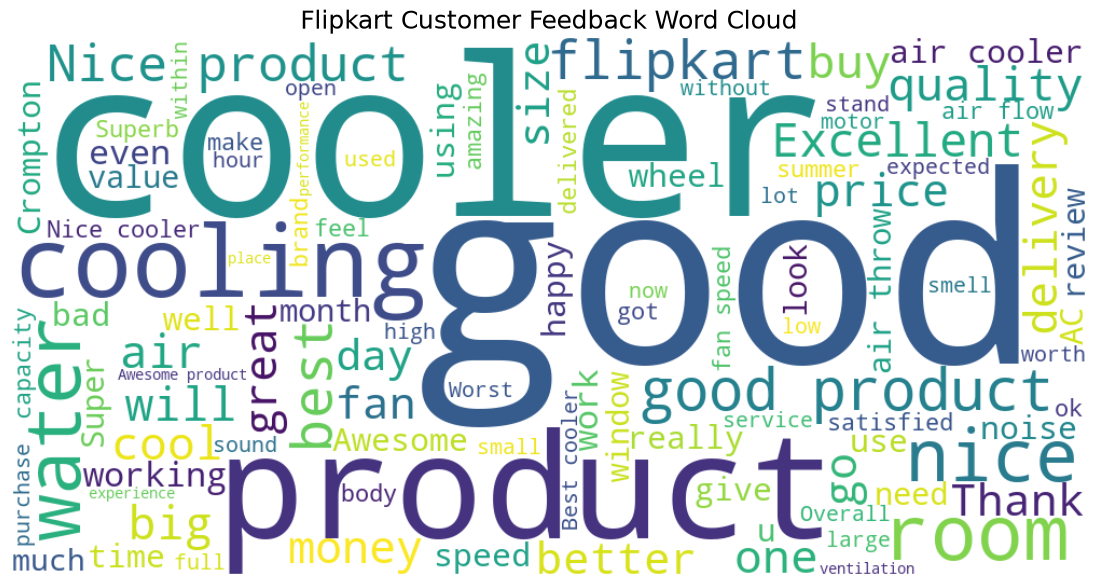

In [18]:
plt.figure(figsize=(15, 7))

plt.imshow(wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title(
    'Flipkart Customer Feedback Word Cloud',
    fontsize=18
)

plt.show()

In [19]:
wordcloud.to_file("flipkart_wordcloud.png")